# Discovering laws 3: Mercury doesn't fit

*Learning path: discovering physical laws, part 3 of 4.* [Index](README.md) · Previous: [From Kepler to Newton](02-newton.ipynb) · Next: [Deriving the precession](04-precession.ipynb)

Newton's law explained the planets so well that astronomers used it to predict a new planet, Neptune, which was found
in 1846 exactly where Urbain Le Verrier said it would be. Le Verrier then turned to Mercury and found something no
planet could explain: its orbit slowly turns, a little faster than Newton allows [1]. In this lesson you will look at
the evidence and let Galileo find what kind of correction to Newton's law fits it. You will learn

* how to work with observations that have **uncertainties**, and what $\chi^2$ means,
* how to compare several hypotheses at once with `check`,
* how a **scaling law** across several bodies points to one specific term in the orbit equation,
* why that term could never have been found from positions alone.

## 1. Forty-three arcseconds

The perihelion of Mercury, its closest point to the Sun, moves around the Sun: about 574 arcseconds per century
measured against the distant stars (an arcsecond, ″, is 1/3600 of a degree). Almost all of it is caused by the other
planets tugging on Mercury, which Newton's theory computes very precisely. In 1947 Gerald Clemence summarised a century
of observations and calculations [2]:

In [1]:
observed = 574.10;
planets_effect = 531.54;
observed - planets_effect

42.56

That leaves $42.56″ \pm 0.94″$ per century unexplained (the uncertainty combines the observations and the masses used
for the planets). It is tiny: Mercury's orbit would take three million years to turn around once because of it. But it
is 45 times the uncertainty, and every attempt to explain it within Newton's theory failed, including an unseen planet
"Vulcan" inside Mercury's orbit, which was searched for and never found.

## 2. More than one planet

A single number allows many explanations. The key is to measure the same effect for several bodies. By the 1970s,
radar echoes from the planets measured the unexplained part of the perihelion motion for Venus and Earth too, and for
the asteroid Icarus, which comes closer to the Sun than Mercury on a very stretched orbit [3]. Each row of the table
below is one body, with five columns:

1. $a$, the semi-major axis in AU,
2. the eccentricity (0 for a circle, close to 1 for a very stretched ellipse), named `ecc` because `e` is Euler's
   number in Galileo,
3. $T$, the period in years,
4. $d$, the unexplained perihelion motion in arcseconds per century,
5. $s$, its uncertainty (one standard deviation), in the same units.

In [2]:
perihelia = [0.3871 0.2056 0.2408 43.11 0.45; 0.7233 0.0068 0.6152 8.4 4.8; 1.000 0.0167 1.000 5.0 1.2; 1.078 0.827 1.12 9.8 0.8];

Two changes of variable make the physics clearer:

* Per orbit instead of per century: a body makes $100/T$ orbits per century, so the turn per orbit is
  $w = d \cdot T/100$, in arcseconds. Its uncertainty scales the same way.
* The size of an orbit is best measured by the **semi-latus rectum** $p = a(1 - e^2)$, the distance from the Sun at
  right angles to the long axis. For a circle $p = a$; for Icarus, $p$ is only a third of $a$. In the Binet equation of
  [part 2](02-newton.ipynb), $u'' + u = GM/h^2$, the constant $GM/h^2$ is exactly $1/p$.

`transform` builds the new tables: `pw` with columns $p$ and $w$, and `sw` with the uncertainty of $w$.

In [3]:
pw = transform(perihelia, [a ecc T d s], [a*(1 - ecc^2) d*T/100])
sw = transform(perihelia, [a ecc T d s], [s*T/100]);

[     0.370736756544,  0.10380887999999999;
      0.723266554608, 0.051676799999999995;
          0.99972111,                 0.05;
 0.34072453800000013,  0.10976000000000002]

> `transform`: Makes a new table from a data table: the names label the columns of data, and each expression (in those names) gives one column of the result, computed row by row.

In the plot, each dot is a body: across, $p$ in AU; up, the unexplained turn per orbit in arcseconds. The vertical bars
are the uncertainties, ±1 standard deviation. The fourth argument of `scatter` gives them, one per row.

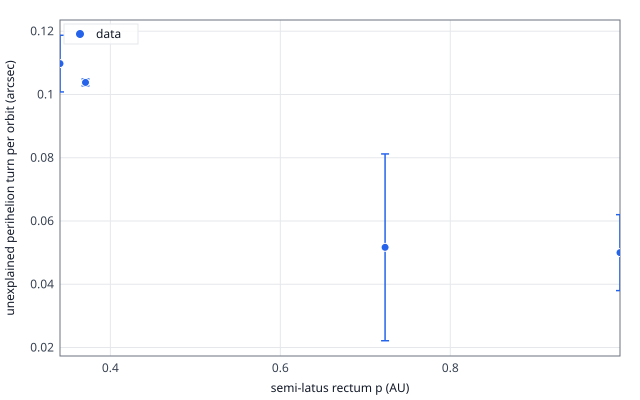

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
labels(scatter(pw, [p w], sw), "semi-latus rectum p (AU)", "unexplained perihelion turn per orbit (arcsec)")

From left to right: Icarus (0.34 AU) and Mercury (0.37), close together and precisely measured, then Venus (0.72)
with a huge error bar, and Earth (1.00). Bodies with smaller orbits turn more.

## 3. Which law?

Three simple hypotheses: the turn per orbit is the same for all ($w = k$), or falls off as $1/p$, or as $1/p^2$. Give
`check` a row of laws, and as fourth argument the uncertainties. In each law, $k$ is not a column, so `check` fits it.

With uncertainties, the misfit is measured by $\chi^2$ per degree of freedom: for each body square the number of
standard deviations between observation and law, add them up, and divide by the number of bodies minus the number of
fitted constants. If the law is right and the uncertainties honest, this is about 1. Much larger means the law is
wrong. `check` calls a law consistent when $\chi^2$/dof is at most 3 and every point is within 3 standard deviations.

In [5]:
check([k, k/p, k/p^2], pw, [p w], sw)

[     0.103;
   0.0385/p;
 0.0142/p^2]

> **check**: 3 formulas for $w$ against 4 observations
>
> | formula | fitted constants | chi2/dof | verdict |
> |---|---|---|---|
> | $w = k$ | $k = 0.1034 \pm 0.003$ | 7.839 | ruled out (row 3 is 4.4σ off) |
> | $w = \frac{k}{p}$ | $k = 0.0385 \pm 0.0004$ | 0.349 | consistent |
> | $w = \frac{k}{p^{2}}$ | $k = 0.0142 \pm 0.0003$ | 3.890 | ruled out (row 3 is 3.0σ off) |

Only $w = k/p$ survives, with $k = 0.0385 \pm 0.0004$ arcsec·AU. The constant law fails because Mercury and Earth
differ by more than their errors; $1/p^2$ fails the other way.

`discover` reaches the same verdict without being told the candidates. With the uncertainties as last argument it
weighs each body by its precision:

In [6]:
discover(pw, [p w], sw)

[                     0.103;
                   0.0385/p;
             0.0536/p^(2/3);
              0.0493/p^0.75;
     0.014*sqrt(p)+0.0353/p;
 0.11*p^2-0.38*sqrt(p)+0.32]

> **discover**: $w$ in terms of $p$, 4 observations
>
> | # | complexity | chi2/dof | formula |
> |---|---|---|---|
> | 0 | 2 | 7.885 | $w = 0.103$ |
> | **1** ★ | 5 | 0.350 | **$w = \frac{0.0385}{p}$** |
> | 2 | 6 | 0.115 | $w = \frac{0.0536}{p^{\frac{2}{3}}}$ |
> | 3 | 7 | 0.078 | $w = \frac{0.0493}{p^{0.75}}$ |
> | 4 | 12 | 0.076 | $w = 0.014 \, \sqrt{p} + \frac{0.0353}{p}$ |
> | 5 | 14 | 0.030 | $w = 0.11 \, p^{2} - 0.38 \, \sqrt{p} + 0.32$ |
>
> ★ best: the simplest formula whose chi2/dof is close to the smallest one (at least two observations per fitted constant)
>
> power-law exponents fitted freely: p: -0.7537 ± 0.2264

Its best formula is $w = 0.0385/p$. The note at the bottom is worth reading too: fitted with a free exponent, the power
law is $p^{-0.75 \pm 0.23}$. That is 1.1 standard deviations from $-1$, but 5 from $-2$ and 3.3 from $0$. Four bodies
cannot tell $-1$ from $-3/4$ (the formula with $p^{-2/3}$ fits as well), and `discover` picks $-1$ because it is the
simplest. Modern data settle it: tracking of the MESSENGER spacecraft around Mercury pins the effect down to a few parts
in $10^5$, exactly as $1/p$ predicts [4].

## 4. From a scaling law to a term in the orbit equation

What change to Newton's law makes orbits turn by an amount proportional to $1/p$? Let's try adding a small term
$\epsilon u^n$ to the Binet equation, for some power $n$:

$$u'' + u = A + \epsilon u^n, \qquad A = \frac{1}{p}.$$

Without the new term, $u$ oscillates around $A$ once per turn of $2\pi$: the orbit closes. With it, write
$u = A + x$ for a small wobble $x$. To first order, $u^n \approx A^n + nA^{n-1}x$, so

$$x'' + \left(1 - n\epsilon A^{n-1}\right)x = \text{constant}.$$

This is a spring with frequency $\omega = \sqrt{1 - n\epsilon A^{n-1}}$. The perihelion (largest $u$) comes back after
an angle $2\pi/\omega$ instead of $2\pi$, so each orbit the perihelion advances by $2\pi/\omega - 2\pi$. For small
$\epsilon$ we only need the first term of its Taylor series. `taylor(f, epsilon, 0, 1)` gives the Taylor polynomial of
$f$ in $\epsilon$ around 0 up to $\epsilon^1$. For $n = 2$:

In [7]:
taylor(2*pi/sqrt(1 - 2*epsilon*A), epsilon, 0, 1) - 2*pi

2*pi*A*epsilon

and for $n = 3$:

In [8]:
taylor(2*pi/sqrt(1 - 3*epsilon*A^2), epsilon, 0, 1) - 2*pi

3*pi*A^2*epsilon

In general the advance per orbit is $\pi n \epsilon A^{n-1} = \pi n\epsilon/p^{\,n-1}$ (the square root must be real
and nonzero, which holds for small $\epsilon$).

So the scaling with $p$ tells us the power: $1/p$ means $n - 1 = 1$, so $n = 2$. **The data ask for a $u^2$ term**,
$u'' + u = A + \epsilon u^2$. A $u^3$ term would give $1/p^2$, which `check` ruled out; a constant force on top of
gravity would give yet another pattern.

And the size: with $n = 2$ the advance is $2\pi\epsilon/p$, and we measured $k = 0.0385$ arcsec·AU. Converting
arcseconds to radians (divide by 206265) and AU to km (times $1.496 \times 10^8$):

In [9]:
eps_km = eval(0.0385/206265/(2*pi)*1.496e8)

4.444131627915936

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

$\epsilon \approx 4.4$ km. A length, and a small one, for the Sun. Hold on to that number for the next lesson.

## 5. Could `discover` have found the $u^2$ term from an orbit?

In [part 2](02-newton.ipynb), `discover` found the Binet equation from Mars's positions. Can it find the extra term
too? First on an invented orbit where the effect is huge: $\epsilon = 0.05$ with $A = 1$, so the correction is 5% of
the force. `odedata` solves the equation and returns a table. Written as two first-order equations,
$u' = v$ and $v' = 1 - u + 0.05u^2$, its arguments are

1. `[v, 1 - u + 0.05*u^2]`, the right-hand sides, $u'$ and $v'$;
2. `[u v]`, the unknowns, in the same order;
3. `phi`, the variable we integrate over;
4. `[1.4 0]`, the starting values $u = 1.4$ (perihelion) and $v = 0$;
5. and 6. `0, 30`, the range of $\phi$ (almost five turns);
7. `600`, the number of steps; the table has 601 rows $[\phi\ u\ v]$.

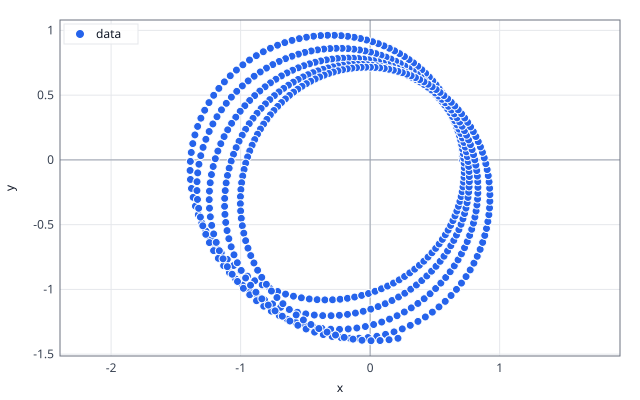

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
tab = odedata([v, 1 - u + 0.05*u^2], [u v], phi, [1.4 0], 0, 30, 600);
labels(scatter(tab, [phi u v], [cos(phi)/u sin(phi)/u]), "x", "y")

The plot shows the orbit, $x = r\cos\phi$ and $y = r\sin\phi$ with $r = 1/u$, in units where $p = 1$: a rosette, the
ellipse turning a little each time. Now ask for $u''$ in terms of powers of $u$:

In [11]:
discover(tab, [phi d(u, phi, 2) v], [1 u u^2 u^3])

[            0.001;
          -0.043*u;
        -0.069*u^3;
 0.94699-0.89424*u;
      0.05*u^2-u+1]

> **discover**: $u''$ in terms of $\phi$, $u$, $v$, 597 observations ($u''$ estimated from neighbouring rows)
>
> | # | complexity | error | formula |
> |---|---|---|---|
> | 0 | 2 | 100% | $u'' = 0.001$ |
> | 1 | 4 | 98% | $u'' = -0.043 \, u$ |
> | 2 | 5 | 86% | $u'' = -0.069 \, u^{3}$ |
> | 3 | 7 | 0.96% | $u'' = 0.94699 - 0.89424 \, u$ |
> | **4** ★ | 10 | 6e-6% | **$u'' = 0.05 \, u^{2} - u + 1$** |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)

Exactly right: $u'' = 1 - u + 0.05u^2$. On perfect data, `discover` finds the extra term.

Now the trap that part 2 warned about. Take an orbit *without* the extra term, and allow $\cos\phi$ as a building block:

In [12]:
newton = odedata([v, 1 - u], [u v], phi, [1.4 0], 0, 30, 600);
discover(newton, [phi d(u, phi, 2) v], [1 u u^2 cos(phi)])

[                         0.014;
                  -2*cos(phi)/5;
          4.3e-9*u-2*cos(phi)/5;
          7e-9*u^2-2*cos(phi)/5;
 3.4e-8*u^2-2*cos(phi)/5-3.7e-8]

> **discover**: $u''$ in terms of $\phi$, $u$, $v$, 597 observations ($u''$ estimated from neighbouring rows)
>
> | # | complexity | error | formula |
> |---|---|---|---|
> | 0 | 2 | 100% | $u'' = 0.014$ |
> | **1** ★ | 4 | 7e-6% | **$u'' = -\frac{2 \, \cos\left(\phi\right)}{5}$** |
> | 2 | 9 | 7e-6% | $u'' = 4.3\times 10^{-9} \, u - \frac{2 \, \cos\left(\phi\right)}{5}$ |
> | 3 | 10 | 6e-6% | $u'' = 7\times 10^{-9} \, u^{2} - \frac{2 \, \cos\left(\phi\right)}{5}$ |
> | 4 | 12 | 7e-7% | $u'' = 3.4\times 10^{-8} \, u^{2} - \frac{2 \, \cos\left(\phi\right)}{5} - 3.7\times 10^{-8}$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)

The best formula is $u'' = -\tfrac25\cos\phi$, and it is true: this orbit is $u = 1 + 0.4\cos\phi$, so on it
$-\tfrac25\cos\phi$ and $1 - u$ are the same numbers. But it describes one orbit, not the law; start the planet
elsewhere and it fails. The law, $u'' = 1 - u$, fits these data just as exactly, yet it never appears: with the cosine
available it is not needed, and rows 2 to 4 only add terms whose coefficients are zero up to rounding. `discover` ranks
by simplicity, and only you know which building blocks make sense.

**Why real positions can't do it.** For Mercury, the $u^2$ term compared with the $u$ term is $\epsilon u = \epsilon/r \approx 4.4\text{ km}/58\text{ million km} \approx 8 \times 10^{-8}$. Positions accurate to better than one part in
$10^8$, differentiated twice, are far beyond any telescope. The effect was found because it *accumulates*: $0.1″$ per
orbit, 415 orbits per century, over two centuries of observations. That is why the data in this lesson are perihelion
rates, not positions.

## 6. What we have, and what we don't

From the data we found: the extra motion scales as $1/p$ across four bodies; within the Binet equation that means an
extra term $\epsilon u^2$; and $\epsilon \approx 4.4$ km. That is a real discovery, and it is as far as data can go.

What the data cannot say is *why*. A $u^2$ term corresponds to an extra attraction falling off as $1/r^4$; nothing in
Newton's theory produces one with this strength. In 1915 Einstein derived exactly this term, with
$\epsilon = 3GM/c^2$, from a theory in which gravity is the curvature of spacetime [5]. No fit to planetary data could
have produced that idea. The [last lesson](04-precession.ipynb) checks that Einstein's term is the one we found.

## Sources

Numbers in square brackets in the text refer to this list.

1. U. Le Verrier, "Lettre de M. Le Verrier à M. Faye sur la théorie de Mercure et sur le mouvement du périhélie de
   cette planète", *Comptes rendus de l'Académie des sciences* **49**, 379–383 (1859).
2. G. M. Clemence, "The relativity effect in planetary motions", *Reviews of Modern Physics* **19**, 361–364 (1947):
   observed 574.10″ ± 0.65″ per century relative to the stars, planetary perturbations 531.54″, residual
   42.56″ ± 0.94″. [doi:10.1103/RevModPhys.19.361](https://doi.org/10.1103/RevModPhys.19.361)
3. S. Weinberg, *Gravitation and Cosmology*, Wiley (1972), section 8.6, p. 198: observed excess perihelion motion
   (″ per century) Mercury 43.11 ± 0.45, Venus 8.4 ± 4.8, Earth 5.0 ± 1.2, Icarus 9.8 ± 0.8, from radar and optical
   data analysed by I. I. Shapiro and collaborators. Orbital elements: NASA fact sheets and, for Icarus, the JPL
   Small-Body Database ($a$ = 1.078 AU, $e$ = 0.827, period 1.12 years).
4. R. S. Park et al., "Precession of Mercury's perihelion from ranging to the MESSENGER spacecraft", *Astronomical
   Journal* **153**, 121 (2017). [doi:10.3847/1538-3881/aa5be2](https://doi.org/10.3847/1538-3881/aa5be2)
5. A. Einstein, "Erklärung der Perihelbewegung des Merkur aus der allgemeinen Relativitätstheorie", *Sitzungsberichte
   der Preußischen Akademie der Wissenschaften*, 831–839 (18 November 1915).

Next: [Deriving the precession](04-precession.ipynb): from Einstein's orbit equation to $6\pi GM/(c^2 p)$, step by step.